# BBO capstone: method and results

Eight hidden functions take 2 to 8 inputs between 0 and 1 and return one number each. The goal is to find the inputs that give each function's highest value, with only one query per function per week. Over 13 weeks, that's 13 queries per function on top of the course's initial data.

This notebook walks through the final method and its results. The method's code lives in [week13.py](week13.py), and the notebook imports it, so there's only one copy of the code. Running every cell takes about a minute, and nothing is submitted anywhere.

More detail is in the [README](../README.md) and in [documentation/](../documentation/): the datasheet, the model card and the week-by-week technical approach.

## 1. Setup

In [1]:
import warnings

# Known, harmless warnings, silenced before the libraries load:
warnings.filterwarnings("ignore", category=FutureWarning)  # a deprecation inside a library (torch.jit)
from botorch.exceptions.warnings import OptimizationWarning
from gpytorch.utils.warnings import NumericalWarning
warnings.filterwarnings("ignore", category=OptimizationWarning)  # L-BFGS-B stopping early on flat surfaces
warnings.filterwarnings("ignore", category=NumericalWarning)  # function 4's near-zero noise, rounded up

from contextlib import redirect_stdout
from io import StringIO

import matplotlib.pyplot as plt
import numpy as np
import torch

import week13 as bbo  # the final method: data loading, models, search and graphs

plt.rcParams.update(bbo.PLOT_STYLE)
ALL_WEEKS = list(range(1, 14))  # every round with results
FINAL_ROUND_DATA = list(range(1, 13))  # the data available when the final (week 13) queries were chosen

## 2. The data

Each function starts with the course's initial data, and gains one query and its result every week. The initial data looks uniformly random; the weekly queries concentrate around each function's best point.

In [2]:
print(f"{'Function':>8} {'Inputs':>6} {'Initial':>7} {'Weekly':>6} {'Best initial':>13} {'Best final':>11} {'Week':>5}")
for f in range(1, 9):
    X, y, n_initial = bbo.load_data(f, ALL_WEEKS)
    best = np.argmax(y)
    week = "init" if best < n_initial else best - n_initial + 1  # the week of the best result
    print(f"{f:>8} {X.shape[1]:>6} {n_initial:>7} {len(y) - n_initial:>6} "
          f"{y[:n_initial].max():>13.6g} {y.max():>11.6g} {week:>5}")

Function Inputs Initial Weekly  Best initial  Best final  Week
       1      2      10     13   7.71088e-16     1.99938    13
       2      2      10     13      0.611205    0.717634    10
       3      3      15     13    -0.0348353 -0.000703991    11
       4      4      30     13      -4.02554    0.570867    10
       5      4      20     13       1088.86     8662.48     5
       6      5      20     13     -0.714265     -0.1529    13
       7      6      30     13       1.36497     3.18182    13
       8      8      40     13       9.59848     9.98912    13


## 3. The method

Each function has a few settings, chosen from its brief and from tests on the data:

- **Functions 2 to 8: Bayesian optimisation.** A Gaussian process (GP) is fitted to every observation. It's a model that predicts each point's value together with its uncertainty.
  - *Choosing the query:* the next query is the point with the highest *Log Expected Improvement*, the amount it's expected to beat the best value by.
  - *Where it searches:* only inside a *trust region*, a box around the best point. The box doubles after a week that improved the best value and halves after one that didn't.
  - *Output scales:* function 3 is modelled on −log(−y), since it can't exceed 0, and function 5 on log(y), since it spans 0.1 to 8,662.
  - *Noise:* function 4's GP treats every observation as exact.
- **Function 1: a radiation-source model.** Its readings are almost all about 0, which a GP can't learn from. The size of a reading falls off with distance from a source, so a least-squares fit of a bowl to the log of the readings locates it.
- **Function 7** matches the Hartmann-6 benchmark, but it's treated as a black box like the others.

In [3]:
for f, settings in bbo.SETTINGS.items():
    print(f"Function {f}: {settings}")

Function 1: {'method': 'source'}
Function 2: {'method': 'gp'}
Function 3: {'method': 'gp', 'transform': 'neg_log'}
Function 4: {'method': 'gp', 'noise_free': True}
Function 5: {'method': 'gp', 'transform': 'log'}
Function 6: {'method': 'gp'}
Function 7: {'method': 'gp'}
Function 8: {'method': 'gp'}


### Example: function 8, a GP function

This is the final-round decision for function 8, using the data up to week 12. The method prints the trust region's size, its prediction and the GP's length scales: a smaller length scale means the input matters more.

The graph has two parts:
- **History:** each observation in order, with the best so far.
- **Slices:** one per input, through the next query, varying that input alone. The dots are every observation projected onto that input.

This query was submitted as it is, and it gave a new best, 9.989.

  trust region side length: 0.125
  GP predicts y ≈ 9.976 here (68% range 9.964 to 9.988)
  length scales (smaller = input matters more): [ 1.317  1.934  1.041  1.843  2.667  2.266  1.369 15.61 ]
next query: 0.141742-0.150552-0.167304-0.164967-0.793873-0.496895-0.230659-0.704508


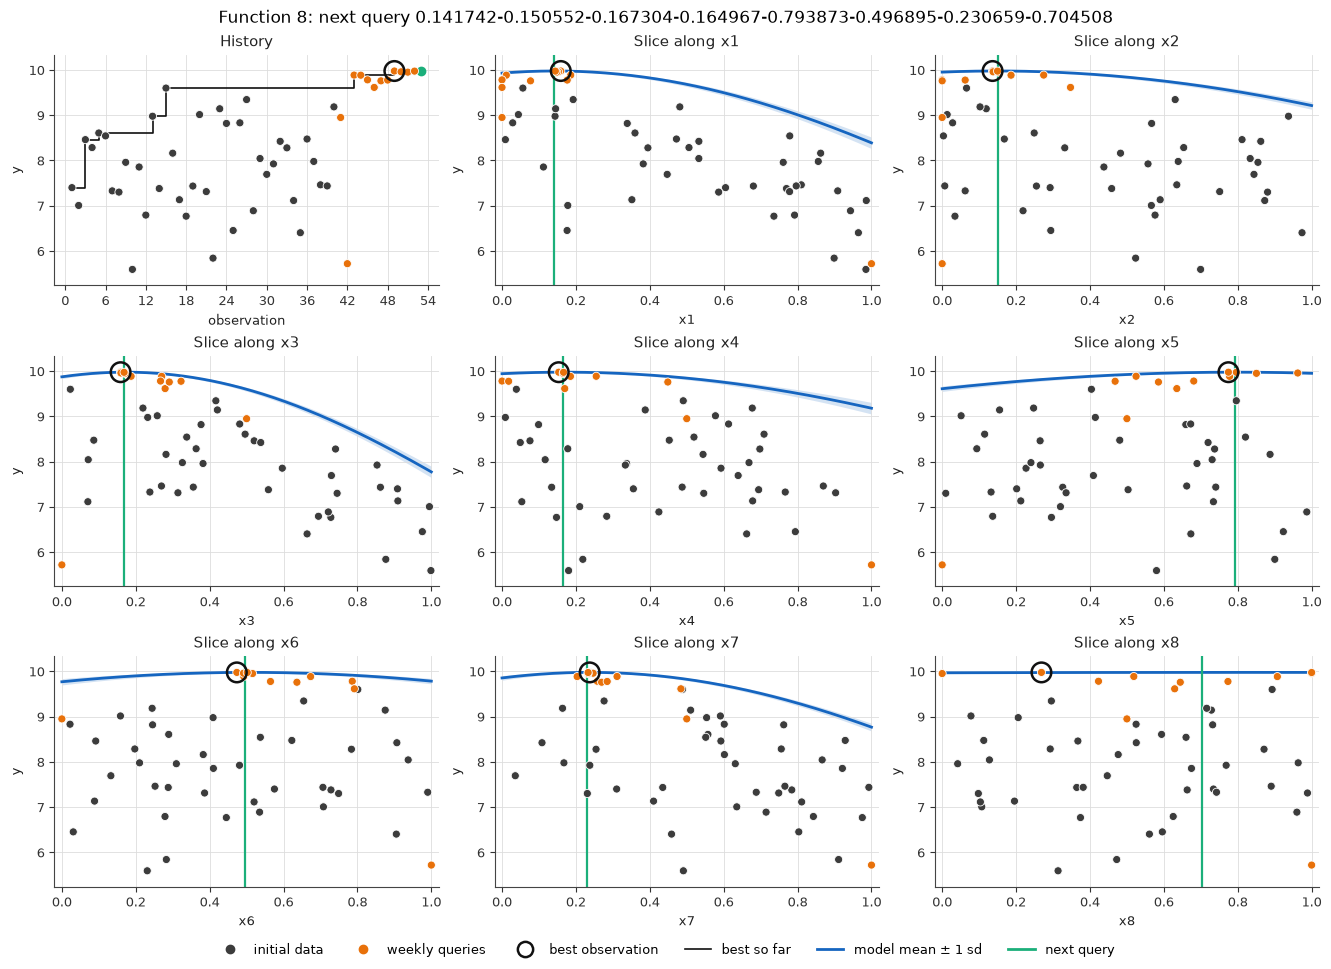

In [4]:
torch.manual_seed(0)
X, y, n_initial = bbo.load_data(8, FINAL_ROUND_DATA)
length = bbo.trust_region_length(y, n_initial, FINAL_ROUND_DATA)
x_next, t, label, predict = bbo.propose_gp(X, y, None, length)
print("next query:", bbo.format_query(x_next))
fig = bbo.plot_function(8, X, y, n_initial, x_next, t, label, predict)
plt.show()

### Example: function 1, the radiation source

The source model is fitted to the log of each reading's size, so the graph's colours and slices are on that scale.

The model found the source, and its week 9 query gave the first real reading, 1.99. But it's fitted mostly to faint, distant readings, so it can't place the peak finely: its final-round query drifts away from the best reading.

  source model fitted to 17 readings (typical error: 0.5 orders of magnitude)
  predicted |y| at the source centre ≈ 1.5
next query: 0.627136-0.627729


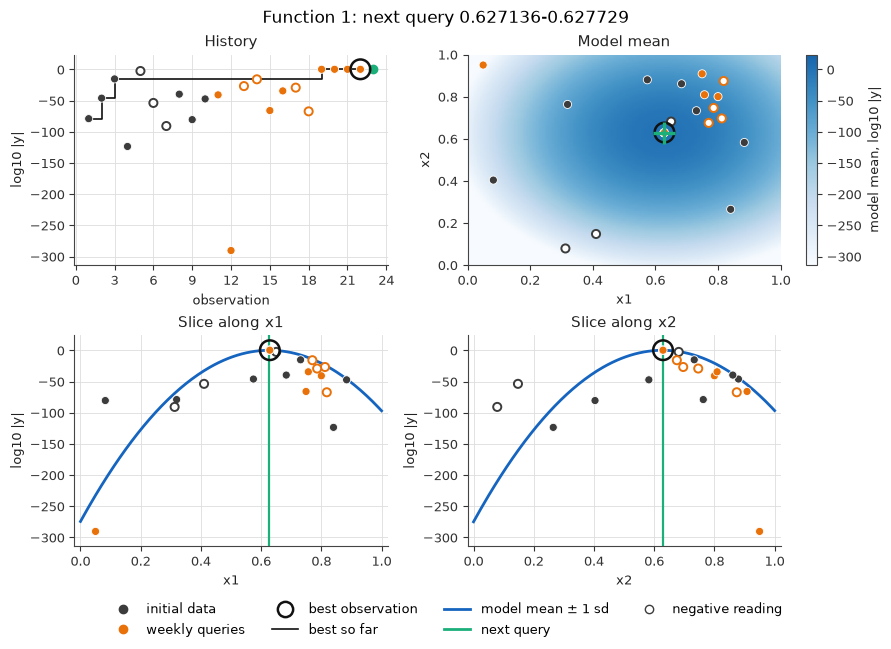

In [5]:
X, y, n_initial = bbo.load_data(1, FINAL_ROUND_DATA)
x_next, t, label, predict = bbo.propose_source(X, y)
print("next query:", bbo.format_query(x_next))
fig = bbo.plot_function(1, X, y, n_initial, x_next, t, label, predict)
plt.show()

For the final round, function 1's query was set by hand instead. The four readings nearest the source (weeks 9 to 12) lie almost on a line, so a curve through them locates the peak along that line:

In [6]:
X, y, n_initial = bbo.load_data(1, FINAL_ROUND_DATA)
near, readings = X[-4:], y[-4:]  # weeks 9-12
origin = near[0]
direction = (near[-1] - origin) / np.linalg.norm(near[-1] - origin)
position = (near - origin) @ direction  # each reading's position along the line
c2, c1, c0 = np.polyfit(position, readings, 2)  # a parabola through the readings
peak = -c1 / (2 * c2)
print("readings:", readings.round(5))
print(f"predicted peak {c0 + c1 * peak + c2 * peak ** 2:.5f} at {bbo.format_query(origin + peak * direction)}")
print(f"week 13 result: {bbo.load_data(1, ALL_WEEKS)[1][-1]:.5f}")

readings: [1.99313 1.99046 1.98899 1.99662]
predicted peak 1.99937 at 0.628295-0.628804
week 13 result: 1.99938


## 4. Reproducing the final queries

Fixed random seeds make the method deterministic: the same data always gives the same query. Rerunning it on the data up to week 12 regenerates the code's final-round queries. Five of the submitted queries were set by hand instead, where local evidence contradicted the model; [technical_approach.md](../documentation/technical_approach.md) lists each one with its reason and result.

In [7]:
torch.manual_seed(0)
submitted = (bbo.ROOT / "weekly_data/week13_inputs.txt").read_text().splitlines()
for f in range(1, 9):
    X, y, n_initial = bbo.load_data(f, FINAL_ROUND_DATA)
    with redirect_stdout(StringIO()):  # hide the method's report, shown above for two functions
        if bbo.SETTINGS[f]["method"] == "source":
            x_next = bbo.propose_source(X, y)[0]
        else:
            length = bbo.trust_region_length(y, n_initial, FINAL_ROUND_DATA)
            x_next = bbo.propose_gp(X, y, bbo.SETTINGS[f].get("transform"), length,
                                    bbo.SETTINGS[f].get("noise_free", False))[0]
    query = bbo.format_query(x_next)
    source = "code" if query == submitted[f - 1] else "set by hand"
    print(f"Function {f}: code {query}\n            submitted {submitted[f - 1]} ({source})")

Function 1: code 0.627136-0.627729
            submitted 0.628295-0.628804 (set by hand)
Function 2: code 0.690102-0.565180
            submitted 0.690102-0.565180 (code)
Function 3: code 1.000000-0.510178-0.454529
            submitted 1.000000-0.525000-0.450318 (set by hand)


Function 4: code 0.408935-0.336399-0.382465-0.338036
            submitted 0.393456-0.365479-0.376885-0.409609 (set by hand)
Function 5: code 1.000000-1.000000-1.000000-1.000000
            submitted 1.000000-1.000000-1.000000-1.000000 (code)


Function 6: code 0.468315-0.357683-0.714454-0.835230-0.000000
            submitted 0.420012-0.349150-0.641525-0.817656-0.000000 (set by hand)


Function 7: code 0.227921-0.143902-0.401202-0.304421-0.329339-0.641301
            submitted 0.215508-0.098979-0.421262-0.319386-0.335008-0.645428 (set by hand)


Function 8: code 0.141742-0.150552-0.167304-0.164967-0.793873-0.496895-0.230659-0.704508
            submitted 0.141742-0.150552-0.167304-0.164967-0.793873-0.496895-0.230659-0.704508 (code)


## 5. Results

The best result so far for each function, by week. Week 0 is the initial data, and orange marks a new best.

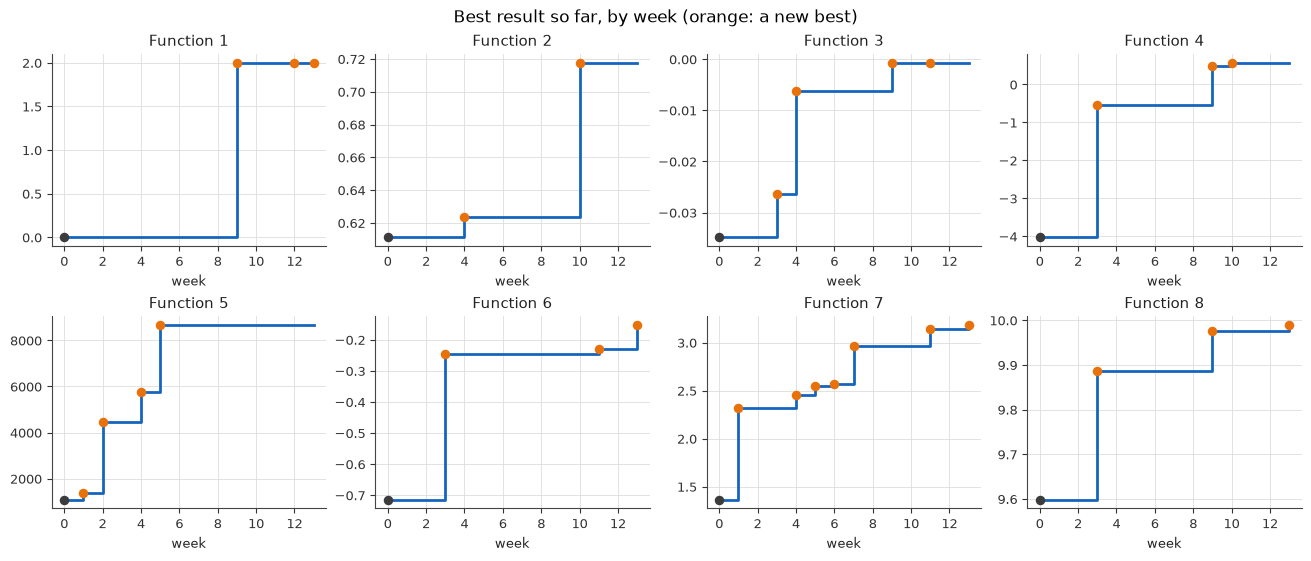

In [8]:
fig = bbo.plot_progress(ALL_WEEKS)
plt.show()

- **Improvement:** every function beat its initial data. The final method, used from week 9, improved seven of the eight. Function 5 was already at its maximum, the (1, 1, 1, 1) corner, which repeats confirmed.
- **Function 1:** it went from no signal at all to 1.999, by locating the radiation source.
- **Function 7:** the only function with a known maximum, 3.32. The final value, 3.18, is 96% of it.
- **Uncertainty:** the GP's uncertainty was too narrow. Only about a quarter of results fell inside its 68% range, against the two thirds expected, so its predictions were optimistic.
- **Noise:** each function's noise assumption mattered more than any other setting. Function 4's noise-free GP overshot repeatedly, while function 5 turned out fully deterministic.
- **Hand-set queries:** four of the seven that aimed to beat the best value did. The ones that worked stayed close to points already measured.

The [model card](../documentation/model_card.md) and the [datasheet](../documentation/datasheet.md) discuss these results, and the method's limitations, in more detail.